# 02. Análisis Exploratorio de Datos Espaciales (AEDE)

**Proyecto:** GeoBanca Norte Perú · **Curso:** Estadística Espacial (UNMSM, 2026-II) · **Semana 2 del sílabo**

**Objetivo del notebook:** describir el acceso a canales financieros en los 327 distritos de la Macro Región Norte
(Tumbes, Piura, Lambayeque, La Libertad y Cajamarca), elegir la variable respuesta del proyecto y detectar
patrones y valores atípicos antes de modelar la dependencia espacial.

**Entrada:** `data/processed/geobanca_norte.gpkg` (capa `distritos`), generado por `src/01_construir_base_distrital.py`.
**Salidas:** figuras en `outputs/figuras/02_*.png` y la variable `acceso_eb` en `data/processed/base_aede.csv`.

In [1]:
# Librerías
from pathlib import Path
import warnings

import geopandas as gpd
import mapclassify as mc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from esda.smoothing import Empirical_Bayes

warnings.filterwarnings("ignore")

# Rutas: el notebook vive en notebooks/, la raíz del proyecto es la carpeta superior
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
FIG = ROOT / "outputs" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

CRS_METRICO = "EPSG:32717"  # UTM 17S: distancias y áreas en metros

# Estilo común de figuras
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORES_DEP = {"TUMBES": "#1b9e77", "PIURA": "#d95f02", "LAMBAYEQUE": "#7570b3",
               "LA LIBERTAD": "#e7298a", "CAJAMARCA": "#66a61e"}

## 1. Carga de datos

In [2]:
g = gpd.read_file(DATA / "geobanca_norte.gpkg", layer="distritos").to_crs(CRS_METRICO)
deps = gpd.GeoDataFrame(geometry=g.dissolve("departamento").geometry, crs=g.crs).reset_index()

print(f"Distritos: {len(g)} | CRS: {g.crs.to_string()} | columnas: {g.shape[1]}")
g[["ubigeo", "distrito", "provincia", "departamento", "pob_total_2025", "pob_18mas",
   "puntos_atencion", "puntos_x10k_adultos", "pobreza_2018"]].head()

Distritos: 327 | CRS: EPSG:32717 | columnas: 41


,ubigeo,distrito,provincia,departamento,pob_total_2025,pob_18mas,puntos_atencion,puntos_x10k_adultos,pobreza_2018
0,060101,CAJAMARCA,CAJAMARCA,CAJAMARCA,242285,181666.401617,4006.0,220.514083,19.748740
1,060102,ASUNCION,CAJAMARCA,CAJAMARCA,7544,5656.525719,21.0,37.125262,58.253570
2,060103,CHETILLA,CAJAMARCA,CAJAMARCA,3340,2504.347283,4.0,15.972226,74.378962
3,060104,COSPAN,CAJAMARCA,CAJAMARCA,6809,5105.419356,32.0,62.678495,73.630185
4,060105,ENCAÑADA,CAJAMARCA,CAJAMARCA,21697,16268.509878,117.0,71.918080,74.909599


## 2. El ámbito por departamento

Primer vistazo agregado: población, puntos de atención (cajeros automáticos + establecimientos con cajeros
corresponsales + EOB + oficinas, de todas las entidades supervisadas por la SBS) y pobreza.

In [3]:
resumen = (g.groupby("departamento")
             .agg(distritos=("ubigeo", "size"),
                  poblacion_2025=("pob_total_2025", "sum"),
                  adultos_est=("pob_18mas", "sum"),
                  puntos_atencion=("puntos_atencion", "sum"),
                  atm=("n_atm", "sum"),
                  oficinas=("n_oficinas", "sum"),
                  pobreza_mediana=("pobreza_2018", "median"),
                  sin_puntos=("sin_punto_atencion", "sum")))
resumen["puntos_x10k_adultos"] = 1e4 * resumen["puntos_atencion"] / resumen["adultos_est"]
resumen.loc["TOTAL"] = resumen.sum(numeric_only=True)
resumen.loc["TOTAL", "pobreza_mediana"] = g["pobreza_2018"].median()
resumen.loc["TOTAL", "puntos_x10k_adultos"] = 1e4 * g["puntos_atencion"].sum() / g["pob_18mas"].sum()
resumen.round(1)

,distritos,poblacion_2025,adultos_est,puntos_atencion,atm,oficinas,pobreza_mediana,sin_puntos,puntos_x10k_adultos
departamento,,,,,,,,,
CAJAMARCA,127.0,1490732.0,1115708.3,15357.0,670.0,153.0,59.8,2.0,137.6
LA LIBERTAD,84.0,2056445.0,1559016.3,19289.0,1319.0,141.0,44.4,3.0,123.7
LAMBAYEQUE,38.0,1404643.0,1062381.1,15015.0,968.0,110.0,18.3,0.0,141.3
PIURA,65.0,2115215.0,1564027.4,21664.0,1769.0,193.0,33.4,0.0,138.5
TUMBES,13.0,256691.0,189727.5,4818.0,215.0,32.0,10.6,0.0,253.9
TOTAL,327.0,7323726.0,5490860.5,76143.0,4941.0,629.0,45.6,5.0,138.7


## 3. Variable de acceso: distribución

La variable candidata es `puntos_x10k_adultos`: puntos de atención por cada 10 mil adultos, la misma métrica
que usa la SBS en sus reportes de inclusión financiera. Revisamos su forma y posibles transformaciones.

                 mean  median    std  skew
original       116.10  102.03  89.25  1.44
log(1+x)         4.38    4.64   1.05 -1.42
raíz cuadrada    9.92   10.10   4.20  0.13


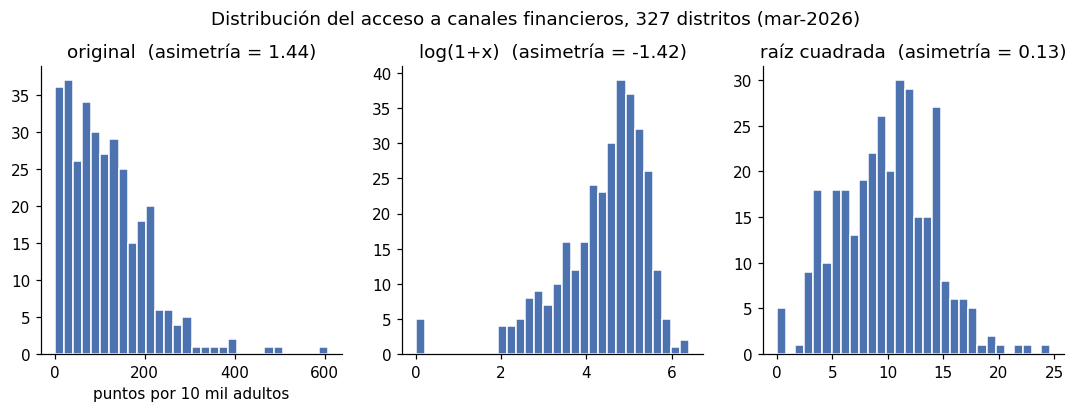

In [4]:
y = g["puntos_x10k_adultos"]
transf = pd.DataFrame({
    "original": y,
    "log(1+x)": np.log1p(y),
    "raíz cuadrada": np.sqrt(y),
})
print(transf.agg(["mean", "median", "std", "skew"]).round(2).T)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, col in zip(axes, transf.columns):
    ax.hist(transf[col], bins=30, color="#4c72b0", edgecolor="white")
    ax.set_title(f"{col}  (asimetría = {transf[col].skew():.2f})")
axes[0].set_xlabel("puntos por 10 mil adultos")
fig.suptitle("Distribución del acceso a canales financieros, 327 distritos (mar-2026)", y=1.03)
fig.savefig(FIG / "02_histogramas_acceso.png", bbox_inches="tight")
plt.show()

## 4. Inestabilidad de tasas en distritos pequeños

Una tasa calculada sobre pocos adultos es muy variable: un distrito de 400 adultos con 20 agentes queda
"arriba" solo por el denominador. El gráfico de embudo lo muestra; la corrección estándar en estadística
espacial es el **suavizado Bayes empírico** (EB), que acerca las tasas de distritos pequeños a la media global
en proporción a su incertidumbre.

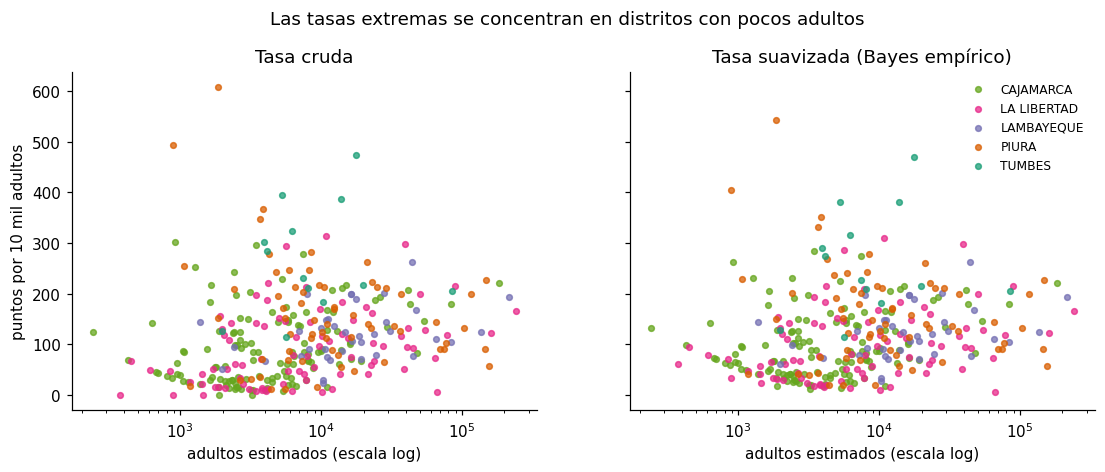

,distrito,provincia,pob_18mas,puntos_atencion,puntos_x10k_adultos,acceso_eb
288,AMOTAPE,PAITA,1842.5,112.0,607.9,543.4
289,ARENAL,PAITA,893.0,44.0,492.7,405.2
323,ZARUMILLA,ZARUMILLA,17699.4,840.0,474.6,469.1
326,PAPAYAL,ZARUMILLA,5244.4,207.0,394.7,381.1
324,AGUAS VERDES,ZARUMILLA,13766.6,532.0,386.4,381.3
292,TAMARINDO,PAITA,3842.0,141.0,367.0,350.8
309,BELLAVISTA DE LA UNION,SECHURA,3711.3,129.0,347.6,332.3
317,PAMPAS DE HOSPITAL,TUMBES,6167.3,200.0,324.3,315.9


In [5]:
eventos = g["puntos_atencion"].to_numpy().reshape(-1, 1)
base = g["pob_18mas"].to_numpy().reshape(-1, 1)
eb = Empirical_Bayes(eventos, base)
g["acceso_eb"] = 1e4 * eb.r.flatten()        # tasa suavizada por 10 mil adultos

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, col, titulo in [(axes[0], "puntos_x10k_adultos", "Tasa cruda"),
                        (axes[1], "acceso_eb", "Tasa suavizada (Bayes empírico)")]:
    for dep, sub in g.groupby("departamento"):
        ax.scatter(sub["pob_18mas"], sub[col], s=14, alpha=0.75, color=COLORES_DEP[dep], label=dep)
    ax.set_xscale("log")
    ax.set_xlabel("adultos estimados (escala log)")
    ax.set_title(titulo)
axes[0].set_ylabel("puntos por 10 mil adultos")
axes[1].legend(frameon=False, fontsize=8)
fig.suptitle("Las tasas extremas se concentran en distritos con pocos adultos", y=1.02)
fig.savefig(FIG / "02_embudo_tasas.png", bbox_inches="tight")
plt.show()

comp = g[["distrito", "provincia", "pob_18mas", "puntos_atencion", "puntos_x10k_adultos", "acceso_eb"]]
comp.sort_values("puntos_x10k_adultos", ascending=False).head(8).round(1)

## 5. Mapas temáticos

Acceso y pobreza en quintiles. La población urbana y los créditos tienen muchos ceros (distritos 100% rurales
o sin oficinas), por eso se usan cortes manuales: con quintiles varias clases quedarían vacías.

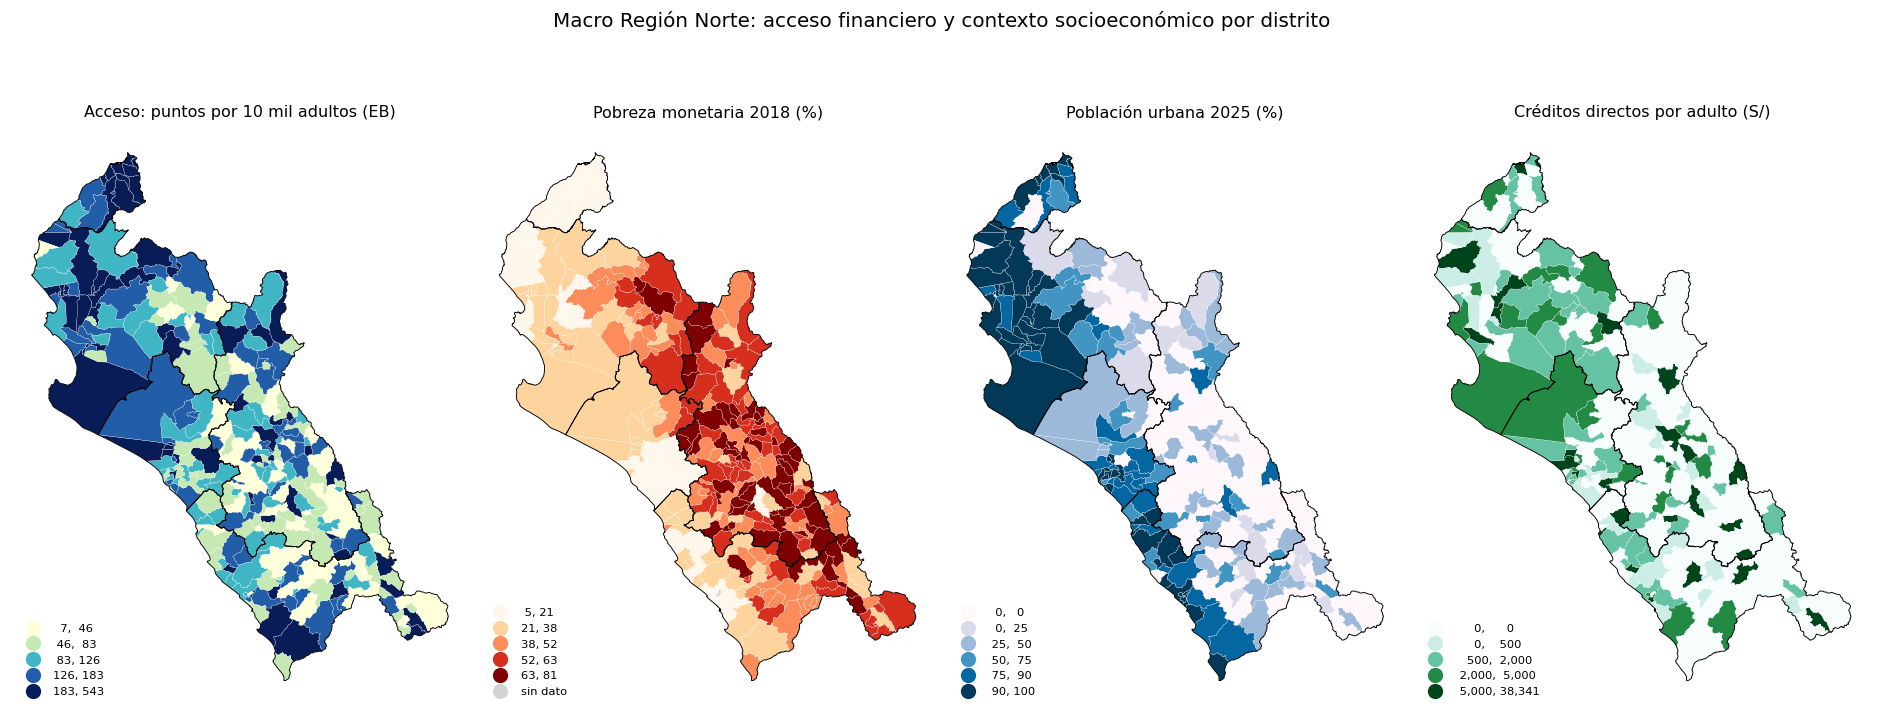

In [6]:
variables = [
    ("acceso_eb", "Acceso: puntos por 10 mil adultos (EB)", "YlGnBu", mc.Quantiles(g["acceso_eb"], k=5).bins),
    ("pobreza_2018", "Pobreza monetaria 2018 (%)", "OrRd", mc.Quantiles(g["pobreza_2018"].dropna(), k=5).bins),
    ("pct_urbana", "Población urbana 2025 (%)", "PuBu", [0, 25, 50, 75, 90, 100]),
    ("creditos_pc_soles", "Créditos directos por adulto (S/)", "BuGn", [0, 500, 2000, 5000, g["creditos_pc_soles"].max()]),
]

fig, axes = plt.subplots(1, 4, figsize=(17, 7.2), constrained_layout=True)
for ax, (col, titulo, cmap, bins) in zip(axes, variables):
    g.plot(column=col, scheme="UserDefined", classification_kwds={"bins": list(bins)}, cmap=cmap, ax=ax,
           edgecolor="white", linewidth=0.15, legend=True,
           legend_kwds={"loc": "lower left", "fontsize": 7.5, "frameon": False, "fmt": "{:,.0f}"},
           missing_kwds={"color": "lightgrey", "label": "sin dato"})
    deps.boundary.plot(ax=ax, color="black", linewidth=0.6)
    ax.set_title(titulo, fontsize=10.5)
    ax.set_axis_off()
fig.suptitle("Macro Región Norte: acceso financiero y contexto socioeconómico por distrito", fontsize=13)
fig.savefig(FIG / "02_mapas_tematicos.png", bbox_inches="tight")
plt.show()

## 6. Boxmap: valores atípicos

El boxmap clasifica cada distrito según la caja del boxplot (bigotes a 1,5 veces el rango intercuartílico),
de modo que los atípicos quedan marcados en el mapa. Se compara la tasa cruda con la suavizada.

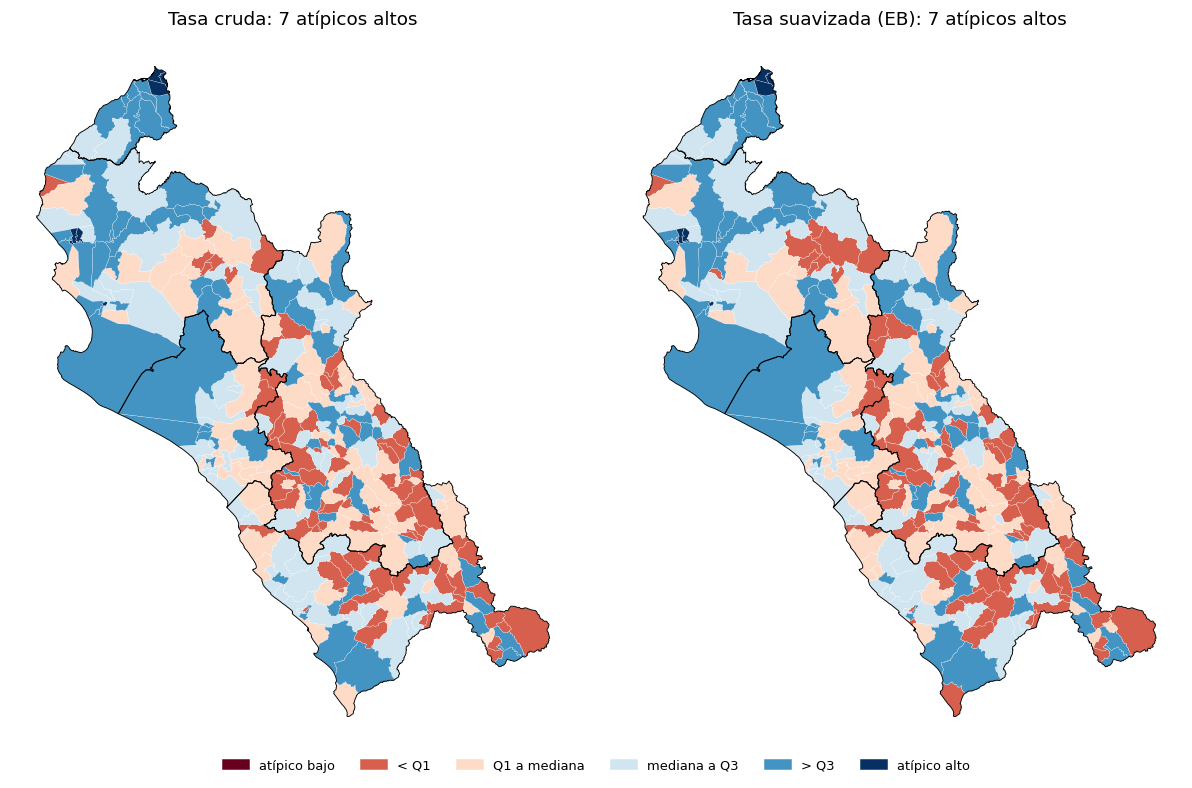

Límites del boxplot (EB): [-95.7  59.4 103.7 162.7 317.8 543.4]


,distrito,provincia,departamento,pob_18mas,acceso_eb
288,AMOTAPE,PAITA,PIURA,1842.5,543.4
323,ZARUMILLA,ZARUMILLA,TUMBES,17699.4,469.1
289,ARENAL,PAITA,PIURA,893.0,405.2
324,AGUAS VERDES,ZARUMILLA,TUMBES,13766.6,381.3
326,PAPAYAL,ZARUMILLA,TUMBES,5244.4,381.1
292,TAMARINDO,PAITA,PIURA,3842.0,350.8
309,BELLAVISTA DE LA UNION,SECHURA,PIURA,3711.3,332.3


In [7]:
CLASES_BOX = ["atípico bajo", "< Q1", "Q1 a mediana", "mediana a Q3", "> Q3", "atípico alto"]
COLORES_BOX = ["#67001f", "#d6604d", "#fddbc7", "#d1e5f0", "#4393c3", "#053061"]

fig, axes = plt.subplots(1, 2, figsize=(11, 6.8), constrained_layout=True)
for ax, col, titulo in [(axes[0], "puntos_x10k_adultos", "Tasa cruda"),
                        (axes[1], "acceso_eb", "Tasa suavizada (EB)")]:
    clas = mc.BoxPlot(g[col])
    for k, color in enumerate(COLORES_BOX):          # se pinta clase por clase para fijar los colores
        sub = g[clas.yb == k]
        if len(sub):
            sub.plot(ax=ax, color=color, edgecolor="white", linewidth=0.15)
    deps.boundary.plot(ax=ax, color="black", linewidth=0.6)
    ax.set_title(f"{titulo}: {(clas.yb == 5).sum()} atípicos altos")
    ax.set_axis_off()
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORES_BOX]
fig.legend(handles, CLASES_BOX, loc="lower center", ncol=6, frameon=False, fontsize=8.5, bbox_to_anchor=(0.5, -0.04))
fig.savefig(FIG / "02_boxmap_acceso.png", bbox_inches="tight")
plt.show()

clas_eb = mc.BoxPlot(g["acceso_eb"])
print("Límites del boxplot (EB):", np.round(clas_eb.bins, 1))
g[clas_eb.yb == 5][["distrito", "provincia", "departamento", "pob_18mas", "acceso_eb"]].sort_values("acceso_eb", ascending=False).round(1)

## 7. Relaciones bivariadas

Correlaciones de Spearman (robustas a la asimetría) entre el acceso suavizado y las covariables candidatas
para la regresión espacial de la semana 4.

pobreza_2018        -0.46
altitud_capital_m   -0.40
densidad_hab_km2     0.28
creditos_pc_soles    0.38
idh_2019             0.45
pct_urbana           0.46


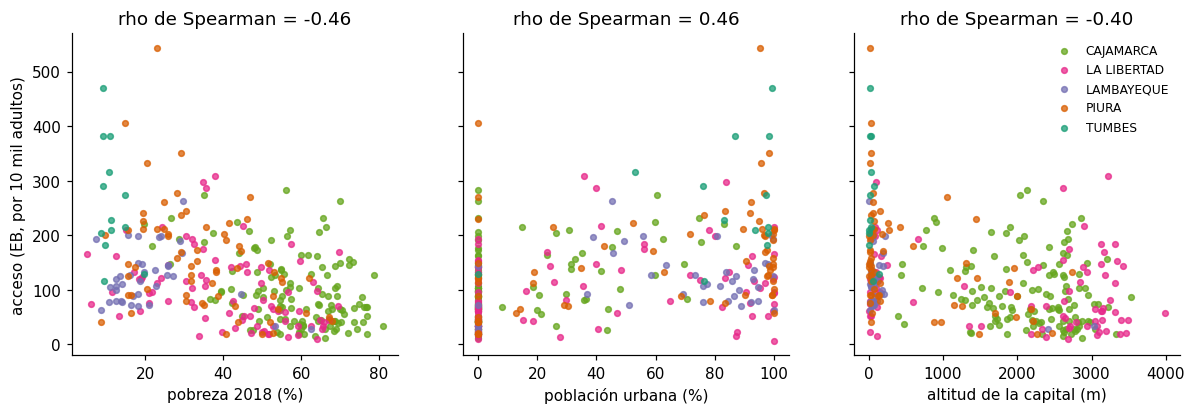

In [8]:
covs = ["pobreza_2018", "idh_2019", "pct_urbana", "densidad_hab_km2", "altitud_capital_m", "creditos_pc_soles"]
corr = g[["acceso_eb"] + covs].corr(method="spearman")["acceso_eb"].drop("acceso_eb").sort_values()
print(corr.round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, col, xl in [(axes[0], "pobreza_2018", "pobreza 2018 (%)"),
                    (axes[1], "pct_urbana", "población urbana (%)"),
                    (axes[2], "altitud_capital_m", "altitud de la capital (m)")]:
    for dep, sub in g.groupby("departamento"):
        ax.scatter(sub[col], sub["acceso_eb"], s=14, alpha=0.75, color=COLORES_DEP[dep], label=dep)
    ax.set_xlabel(xl)
    ax.set_title(f"rho de Spearman = {corr[col]:.2f}")
axes[0].set_ylabel("acceso (EB, por 10 mil adultos)")
axes[2].legend(frameon=False, fontsize=8)
fig.savefig(FIG / "02_dispersion_covariables.png", bbox_inches="tight")
plt.show()

## 8. Estadísticos descriptivos espaciales: centro medio y distancia estándar

¿La oferta de canales está donde vive la gente? Comparamos el centro medio ponderado por población con el
centro medio ponderado por puntos de atención (usando el centroide de cada distrito), y la distancia estándar
(dispersión espacial alrededor del centro).

                     distancia_estandar_km  desplazamiento_vs_poblacion_km
población 2025                       172.4                             0.0
puntos de atención                   179.5                            14.3
cajeros automáticos                  178.0                            29.8


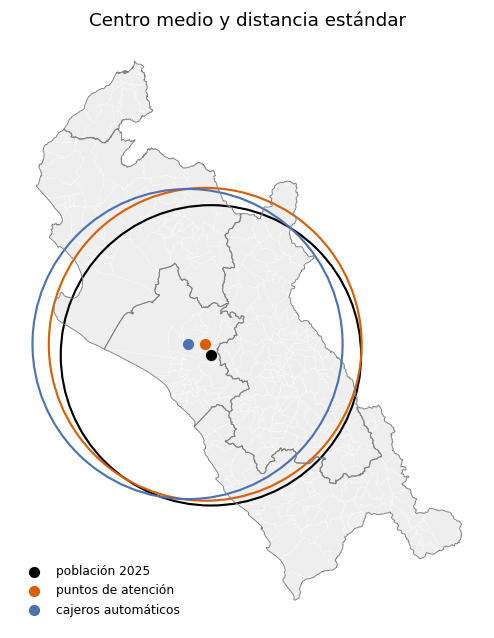

In [9]:
cent = g.geometry.centroid
x, yc = cent.x.to_numpy(), cent.y.to_numpy()

def centro_y_distancia(w):
    w = np.asarray(w, dtype=float)
    mx, my = np.average(x, weights=w), np.average(yc, weights=w)
    ds = np.sqrt(np.average((x - mx) ** 2 + (yc - my) ** 2, weights=w))
    return mx, my, ds

filas = {}
for nombre, w in [("población 2025", g["pob_total_2025"]), ("puntos de atención", g["puntos_atencion"]),
                  ("cajeros automáticos", g["n_atm"])]:
    mx, my, ds = centro_y_distancia(w)
    filas[nombre] = {"x_utm": mx, "y_utm": my, "distancia_estandar_km": ds / 1000}
cm = pd.DataFrame(filas).T
base_pob = cm.loc["población 2025", ["x_utm", "y_utm"]]
cm["desplazamiento_vs_poblacion_km"] = np.hypot(cm["x_utm"] - base_pob["x_utm"], cm["y_utm"] - base_pob["y_utm"]) / 1000
print(cm[["distancia_estandar_km", "desplazamiento_vs_poblacion_km"]].round(1))

fig, ax = plt.subplots(figsize=(6, 7))
g.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
deps.boundary.plot(ax=ax, color="grey", linewidth=0.6)
for (nombre, fila), color in zip(cm.iterrows(), ["black", "#d95f02", "#4c72b0"]):
    ax.add_patch(plt.Circle((fila.x_utm, fila.y_utm), fila.distancia_estandar_km * 1000,
                            fill=False, color=color, linewidth=1.4))
    ax.scatter(fila.x_utm, fila.y_utm, color=color, s=40, zorder=3, label=nombre)
ax.legend(frameon=False, loc="lower left", fontsize=8)
ax.set_title("Centro medio y distancia estándar")
ax.set_axis_off()
fig.savefig(FIG / "02_centro_medio.png", bbox_inches="tight")
plt.show()

## 9. Exportar la variable suavizada

In [10]:
g.drop(columns="geometry").to_csv(DATA / "base_aede.csv", index=False)
print("Guardado:", (DATA / "base_aede.csv").relative_to(ROOT))

Guardado: data/processed/base_aede.csv


## 10. Hallazgos para el proyecto

1. **Hay mucha oferta, pero mal repartida.** El ámbito tiene 139 puntos de atención por 10 mil adultos, aunque la
   mediana distrital es 102 y va de 0 a 608. Tumbes (mediana EB 227) y Piura (141) duplican a Cajamarca (83) y
   La Libertad (80).
2. **El acceso se apoya en los corresponsales.** 237 de 327 distritos no tienen ningún cajero automático y 197 no
   tienen oficina; en ellos el canal es casi siempre el agente corresponsal.
3. **Las tasas crudas engañan en distritos pequeños.** Los valores más altos (Amotape, Arenal) son distritos con
   menos de 2 mil adultos. Se usará la **tasa suavizada por Bayes empírico (`acceso_eb`)** como variable
   respuesta; su distribución es asimétrica (1,44 en la cruda), así que en la regresión conviene la raíz cuadrada
   (asimetría 0,13).
4. **Bajo acceso = sierra pobre.** De los 66 distritos del quintil más bajo de acceso, 57 están en Cajamarca y
   La Libertad, y su pobreza mediana es 60% frente a 38% en el resto. Los mapas sugieren un patrón agrupado,
   no aleatorio: eso se prueba con Moran y LISA en el notebook 03.
5. **Covariables candidatas** (Spearman con `acceso_eb`): % urbana +0,46, IDH +0,45, pobreza -0,46, altitud -0,40.
   Pobreza e IDH miden casi lo mismo; en la regresión se elegirá una para evitar colinealidad.
6. **La oferta está corrida hacia la costa.** El centro medio de los cajeros automáticos está 30 km al oeste del
   centro medio de la población, y el de todos los puntos de atención, 14 km.